<a href="https://colab.research.google.com/github/munnamia1945/AI_ML_DL_CYS_Projects/blob/main/09-mini-rag-document-assistant/mini_rag_document_assistant.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Cell 1 - Project information

In [ ]:
PROJECT_NAME = "Mini RAG Document Assistant"
RANDOM_STATE = 42

print("Project:", PROJECT_NAME)
print("Core components: Chunking, Embeddings, Retrieval, Citations")
print("Evaluation: Retrieval quality and answer quality")

Project: Mini RAG Document Assistant
Core components: Chunking, Embeddings, Retrieval, Citations
Evaluation: Retrieval quality and answer quality


### Cell 2 - Install libraries

In [ ]:
%pip -q install pypdf sentence-transformers transformers accelerate pandas numpy matplotlib seaborn

### Cell 3 - Import libraries and configure device

In [ ]:
import os
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from google.colab import files
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
Device: cuda
GPU: Tesla T4


### Cell 4 - Upload documents
Both PDF and TXT formats can be supported. Multiple files can be uploaded at once


In [ ]:
uploaded = files.upload()

print("\nUploaded files:")
for filename in uploaded:
    print("-", filename)

Saving python_rag_guide.txt to python_rag_guide.txt

Uploaded files:
- python_rag_guide.txt


### Cell 5 — Extract text from documents
For PDFs, I will save each page separately so that the page number can be shown in the citation

In [ ]:
documents = []

for filename in uploaded:
    extension = os.path.splitext(filename)[1].lower()

    if extension == ".pdf":
        reader = PdfReader(filename)

        for page_number, page in enumerate(reader.pages, start=1):
            text = page.extract_text() or ""

            if text.strip():
                documents.append({
                    "source": filename,
                    "page": page_number,
                    "text": text
                })

    elif extension == ".txt":
        with open(filename, "r", encoding="utf-8", errors="ignore") as f:
            text = f.read()

        if text.strip():
            documents.append({
                "source": filename,
                "page": None,
                "text": text
            })

    else:
        print("Skipped unsupported file:", filename)

print("Extracted document sections:", len(documents))
print("Total extracted characters:",
      sum(len(d["text"]) for d in documents))

if not documents:
    raise ValueError(
        "No readable text found. Upload a text-based PDF or TXT file."
    )

display(pd.DataFrame([
    {
        "source": d["source"],
        "page": d["page"],
        "characters": len(d["text"])
    }
    for d in documents
]).head(10))

Extracted document sections: 1
Total extracted characters: 1411


,source,page,characters
0,python_rag_guide.txt,None,1411


### Cell 6 - Split text into chunks

In [ ]:
CHUNK_SIZE = 180       # words
CHUNK_OVERLAP = 40     # words

def split_into_chunks(text, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP):
    words = text.split()
    chunks = []
    step = chunk_size - overlap

    for start in range(0, len(words), step):
        chunk = " ".join(words[start:start + chunk_size])

        if chunk.strip():
            chunks.append(chunk)

        if start + chunk_size >= len(words):
            break

    return chunks

chunks = []

for doc in documents:
    for chunk_index, chunk_text in enumerate(
        split_into_chunks(doc["text"]), start=1
    ):
        chunks.append({
            "source": doc["source"],
            "page": doc["page"],
            "chunk_id": chunk_index,
            "text": chunk_text
        })

chunks_df = pd.DataFrame(chunks)

print("Total chunks:", len(chunks_df))
display(chunks_df.head(3))

if chunks_df.empty:
    raise ValueError("No chunks were created from the uploaded documents.")

Total chunks: 2


,source,page,chunk_id,text
0,python_rag_guide.txt,None,1,Python Basics: A Mini Reference Guide 1. Varia...
1,python_rag_guide.txt,None,2,Machine Learning Machine learning algorithms l...


### Cell 7 - Generate embeddings

The all-MiniLM-L6-v2 sentence embedding model will be used to convert each chunk into a numerical vector



In [ ]:
EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    device=DEVICE
)

chunk_texts = chunks_df["text"].tolist()

embeddings = embedding_model.encode(
    chunk_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("Embedding matrix shape:", embeddings.shape)
print("Embedding dimension:", embeddings.shape[1])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding matrix shape: (2, 384)
Embedding dimension: 384


### Cell 8 - Semantic document retrieval
The query will then be converted into an embedding, and cosine similarity will be calculated against the document chunks.

In [ ]:
def retrieve_documents(question, top_k=4):
    query_embedding = embedding_model.encode(
        [question],
        convert_to_numpy=True,
        normalize_embeddings=True
    )[0]

    # Since embeddings are normalized, dot product equals cosine similarity.
    scores = embeddings @ query_embedding

    top_indices = np.argsort(scores)[::-1][:min(top_k, len(scores))]

    retrieved = []

    for index in top_indices:
        item = chunks[index].copy()
        item["similarity"] = float(scores[index])
        retrieved.append(item)

    return retrieved


# Example retrieval test
demo_question = "What are the main topics discussed in these documents?"

retrieved = retrieve_documents(demo_question, top_k=4)

for rank, item in enumerate(retrieved, start=1):
    print(f"\nRank {rank} | Similarity: {item['similarity']:.4f}")
    print("Source:", item["source"])
    print("Page:", item["page"])
    print("Text:", item["text"][:500])


Rank 1 | Similarity: 0.1017
Source: python_rag_guide.txt
Page: None
Text: Python Basics: A Mini Reference Guide 1. Variables Variables store values in Python. For example, age = 20 assigns the integer 20 to the variable age. 2. Data Types Common Python data types include integers, floating-point numbers, strings, and booleans. Lists store ordered collections of items, while dictionaries store key-value pairs. 3. Conditional Statements The if, elif, and else statements allow a program to make decisions based on conditions. 4. Loops A for loop iterates over items in a s

Rank 2 | Similarity: 0.0541
Source: python_rag_guide.txt
Page: None
Text: Machine Learning Machine learning algorithms learn patterns from data. Classification predicts categories, while regression predicts numerical values. 8. Model Evaluation Classification models can be evaluated using accuracy, precision, recall, and F1-score. Accuracy measures the proportion of correct predictions. Precision measures how many predi

### Cell 9 — Load the answer-generation model
Pretrained FLAN-T5 will be used to generate answers based on the retrieved context.


In [ ]:
GENERATION_MODEL_NAME = "google/flan-t5-base"

tokenizer = AutoTokenizer.from_pretrained(
    GENERATION_MODEL_NAME
)

generation_model = AutoModelForSeq2SeqLM.from_pretrained(
    GENERATION_MODEL_NAME
).to(DEVICE)

generation_model.eval()

print("Answer-generation model:", GENERATION_MODEL_NAME)

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Answer-generation model: google/flan-t5-base


### Cell 10 - Build RAG answers with source citations

In [ ]:
def answer_question(question, top_k=4):
    retrieved = retrieve_documents(question, top_k=top_k)

    if not retrieved:
        return {
            "question": question,
            "answer": "I could not find relevant document evidence.",
            "citations": [],
            "retrieved": []
        }

    context_parts = []

    for i, item in enumerate(retrieved, start=1):
        page_label = (
            f"Page {item['page']}"
            if item["page"] is not None
            else f"Chunk {item['chunk_id']}"
        )

        context_parts.append(
            f"[Source {i}: {item['source']}, {page_label}]\n"
            f"{item['text']}"
        )

    context = "\n\n".join(context_parts)

    prompt = f"""
Answer the question using only the evidence in the context.
If the context does not contain enough information, say:
"I could not find enough information in the provided documents."
Do not invent facts. Keep the answer concise.

Context:
{context}

Question: {question}

Answer:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    ).to(DEVICE)

    with torch.no_grad():
        output_ids = generation_model.generate(
            **inputs,
            max_new_tokens=180,
            num_beams=2,
            do_sample=False
        )

    answer = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    ).strip()

    citations = []

    for item in retrieved:
        citation = {
            "source": item["source"],
            "page": item["page"],
            "chunk_id": item["chunk_id"],
            "similarity": round(item["similarity"], 4)
        }
        citations.append(citation)

    return {
        "question": question,
        "answer": answer,
        "citations": citations,
        "retrieved": retrieved
    }


# Ask your first question
question = input("Ask a question about your documents: ")

response = answer_question(question)

print("\nQUESTION:")
print(response["question"])

print("\nANSWER:")
print(response["answer"])

print("\nSOURCE CITATIONS:")
for citation in response["citations"]:
    if citation["page"] is not None:
        location = f"Page {citation['page']}"
    else:
        location = f"Chunk {citation['chunk_id']}"

    print(
        f"- {citation['source']} — {location} "
        f"(similarity: {citation['similarity']})"
    )

Ask a question about your documents: What is the difference between precision and recall?

QUESTION:
What is the difference between precision and recall?

ANSWER:
Precision measures how many predicted positive cases are actually positive. Recall measures how many actual positive cases are correctly identified. The F1-score combines precision and recall using their harmonic mean.

SOURCE CITATIONS:
- python_rag_guide.txt — Chunk 2 (similarity: 0.5095)
- python_rag_guide.txt — Chunk 1 (similarity: 0.2763)


### Cell 11 - Evaluate retrieval quality

In [ ]:
# Replace these examples with questions answerable from your own documents.
# expected_source must exactly match an uploaded filename.

evaluation_questions = [
    {
        "question": "Write a question whose answer is in your first document.",
        "expected_source": list(
            dict.fromkeys(d["source"] for d in documents)
        )[0]
    }
]

def evaluate_retrieval(eval_questions, k=4):
    rows = []

    for item in eval_questions:
        results = retrieve_documents(item["question"], top_k=k)

        retrieved_sources = list(dict.fromkeys(
            r["source"] for r in results
        ))

        expected_source = item["expected_source"]

        rows.append({
            "question": item["question"],
            "expected_source": expected_source,
            "retrieved_sources": ", ".join(retrieved_sources),
            f"Hit@{k}": int(expected_source in retrieved_sources)
        })

    return pd.DataFrame(rows)


retrieval_eval_df = evaluate_retrieval(
    evaluation_questions,
    k=4
)

display(retrieval_eval_df)

hit_column = "Hit@4"
print("Retrieval Hit@4:",
      round(retrieval_eval_df[hit_column].mean(), 4))

,question,expected_source,retrieved_sources,Hit@4
0,Write a question whose answer is in your first...,python_rag_guide.txt,python_rag_guide.txt,1


Retrieval Hit@4: 1.0


### Cell 12 - Evaluate answer quality
Accuracy alone is insufficient for RAG evaluation due to multiple valid answers. A manual review sheet will be used.

In [ ]:
# Add several questions whose answers you can verify in the documents.
answer_eval_questions = [
    "Write a factual question based on your document."
]

answer_eval_rows = []

for q in answer_eval_questions:
    result = answer_question(q)

    answer_eval_rows.append({
        "question": q,
        "generated_answer": result["answer"],
        "citations": json.dumps(
            result["citations"],
            ensure_ascii=False
        ),
        "relevance_score_1_to_5": None,
        "groundedness_score_1_to_5": None,
        "citation_correct_0_or_1": None,
        "review_notes": ""
    })

answer_eval_df = pd.DataFrame(answer_eval_rows)
display(answer_eval_df)

os.makedirs("project09_outputs", exist_ok=True)

answer_eval_df.to_csv(
    "project09_outputs/answer_quality_review.csv",
    index=False
)

print("Manual answer-quality review template saved.")

,question,generated_answer,citations,relevance_score_1_to_5,groundedness_score_1_to_5,citation_correct_0_or_1,review_notes
0,Write a factual question based on your document.,What is the difference between a python_rag_gu...,"[{""source"": ""python_rag_guide.txt"", ""page"": nu...",None,None,None,


Manual answer-quality review template saved.


### Cell 13 - Visualize retrieval scores

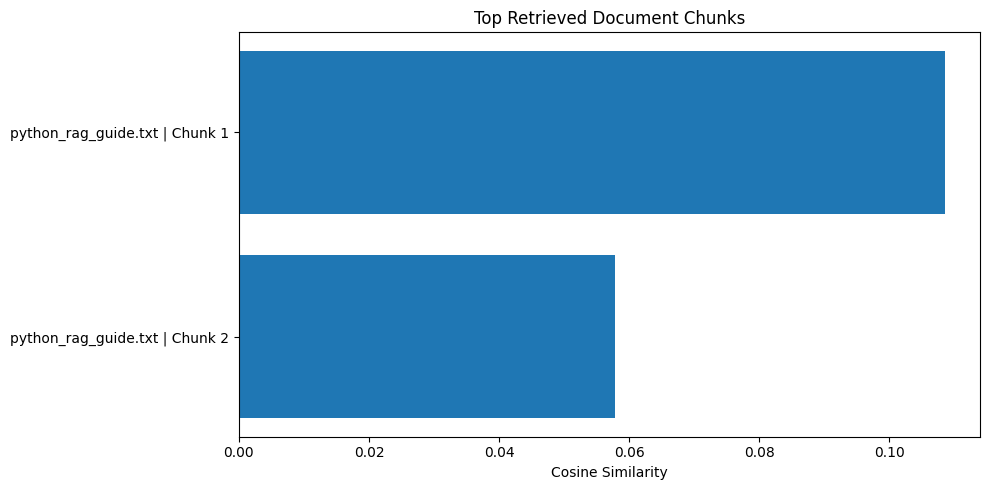

In [ ]:
question_for_plot = (
    evaluation_questions[0]["question"]
)

plot_results = retrieve_documents(
    question_for_plot,
    top_k=5
)

plot_df = pd.DataFrame([
    {
        "source_chunk": (
            f"{item['source']} | "
            f"{'Page ' + str(item['page']) if item['page'] else 'Chunk ' + str(item['chunk_id'])}"
        ),
        "similarity": item["similarity"]
    }
    for item in plot_results
])

plt.figure(figsize=(10, 5))
plt.barh(
    plot_df["source_chunk"][::-1],
    plot_df["similarity"][::-1]
)
plt.xlabel("Cosine Similarity")
plt.title("Top Retrieved Document Chunks")
plt.tight_layout()
plt.show()

Cell 14 - Save project outputs

In [ ]:
OUTPUT_DIR = "project09_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

chunks_df.to_csv(
    f"{OUTPUT_DIR}/document_chunks.csv",
    index=False
)

retrieval_eval_df.to_csv(
    f"{OUTPUT_DIR}/retrieval_evaluation.csv",
    index=False
)

# Save an example Q&A interaction with citations
example_question = evaluation_questions[0]["question"]
example_response = answer_question(example_question)

with open(
    f"{OUTPUT_DIR}/example_rag_response.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "question": example_response["question"],
            "answer": example_response["answer"],
            "citations": example_response["citations"]
        },
        f,
        indent=2,
        ensure_ascii=False
    )

print("Project outputs saved:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

Project outputs saved:
- answer_quality_review.csv
- document_chunks.csv
- example_rag_response.json
- retrieval_evaluation.csv


### Cell 14 - Save project outputs

In [ ]:
OUTPUT_DIR = "project09_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

chunks_df.to_csv(
    f"{OUTPUT_DIR}/document_chunks.csv",
    index=False
)

retrieval_eval_df.to_csv(
    f"{OUTPUT_DIR}/retrieval_evaluation.csv",
    index=False
)

# Save an example Q&A interaction with citations
example_question = evaluation_questions[0]["question"]
example_response = answer_question(example_question)

with open(
    f"{OUTPUT_DIR}/example_rag_response.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        {
            "question": example_response["question"],
            "answer": example_response["answer"],
            "citations": example_response["citations"]
        },
        f,
        indent=2,
        ensure_ascii=False
    )

print("Project outputs saved:")
for filename in sorted(os.listdir(OUTPUT_DIR)):
    print("-", filename)

Project outputs saved:
- answer_quality_review.csv
- document_chunks.csv
- example_rag_response.json
- retrieval_evaluation.csv


### Cell 15 - Final project summary

In [ ]:
print("=" * 60)
print("PROJECT 09: MINI RAG DOCUMENT ASSISTANT")
print("=" * 60)

print("Documents loaded:", len(set(d["source"] for d in documents)))
print("Document sections:", len(documents))
print("Total chunks:", len(chunks))
print("Embedding model:", EMBEDDING_MODEL_NAME)
print("Generation model:", GENERATION_MODEL_NAME)
print("Device:", DEVICE)

print("\nRetrieval evaluation:")
display(retrieval_eval_df)

print("\nAnswer quality review template:")
display(answer_eval_df)

print("\nProject completed.")

PROJECT 09: MINI RAG DOCUMENT ASSISTANT
Documents loaded: 1
Document sections: 1
Total chunks: 2
Embedding model: sentence-transformers/all-MiniLM-L6-v2
Generation model: google/flan-t5-base
Device: cuda

Retrieval evaluation:


,question,expected_source,retrieved_sources,Hit@4
0,Write a question whose answer is in your first...,python_rag_guide.txt,python_rag_guide.txt,1



Answer quality review template:


,question,generated_answer,citations,relevance_score_1_to_5,groundedness_score_1_to_5,citation_correct_0_or_1,review_notes
0,Write a factual question based on your document.,What is the difference between a python_rag_gu...,"[{""source"": ""python_rag_guide.txt"", ""page"": nu...",None,None,None,



Project completed.
